In [ ]:
'''
TRAINING DATASET
Narrow Band Imaging (NBI) images of each detected lesion
non-magnified NBI images, originating from 1,339 unique polyps (73% adenomas, 17% hyperplastic polyps, 10% sessile serrated lesions) detected during 555 different colonoscopies.

VALIDATION DATASET
For each polyp, location, size and morphology (Paris classification) and predicted histology (optical diagnosis) were recorded.

'''

In [48]:
import pandas as pd
import numpy as np
import tkinter as tk
from tkinter import filedialog
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import os
from common import get_image_size
import shutil

In [49]:
# Open file dialog to select the spreadsheet file
spreadsheet_path = filedialog.askopenfilename(
    title="Select the Spreadsheet File",
    filetypes=[("Excel files", "*.xlsx")]
)

# Only annotation on validation data includes information on polyp morphology
validation_folder_path = filedialog.askdirectory(title="Select Validation Set Folder")

In [50]:
# Read the spreadsheet
spreadsheet = pd.ExcelFile(spreadsheet_path)
# Read validation data 
polar_data = pd.read_excel(spreadsheet, 'validation_set')

In [51]:
polar_data[['WIDTH', 'HEIGHT']] = None

for idx, row in polar_data.iterrows():
        patient_folder = os.path.join(validation_folder_path, row['PATIENT_ID'])
        image_id = row['POLYP/IMAGE_ID']
        image_p = os.path.join(patient_folder, image_id + ".png")
        if os.path.exists(image_p):
            properties = get_image_size(image_p)
            polar_data.loc[idx, ['WIDTH', 'HEIGHT']] = properties
polar_data.head()

,PATIENT_ID,POLYP/IMAGE_ID,"POLYP POSITION (x,y,w,h)",POLYP MORPHOLOGY,POLYP SIZE,POLYP LOCATION,OPTICAL DIAGNOSIS,OPTCAL DIAGNOSIS CONFIDENCE,PATHOLOGY DIAGNOSIS,WIDTH,HEIGHT
0,287a18ae061a4f779a02d787f01e823c,57781dbd-5c47-4e9f-985e-62a9077ea9c5,"[75, 468, 260, 325]",Sessile,3,Ascending colon,Adenoma,High,Tubular adenoma,1350,1080
1,287a18ae061a4f779a02d787f01e823c,ddb3f8d6-1f22-4576-8f74-d9d4751a48da,"[62, 593, 436, 389]",Pedunculated,5,Transverse colon,Adenoma,High,Tubular adenoma,1350,1080
2,287a18ae061a4f779a02d787f01e823c,64319dc0-e72d-4902-8084-ecdc17136bdd,"[747, 613, 190, 223]",Sessile,4,Ascending colon,Adenoma,High,Tubular adenoma,1350,1080
3,287a18ae061a4f779a02d787f01e823c,bc673cdc-2e3a-41c7-8b37-cf289a3e42d5,"[641, 726, 165, 162]",Sessile,3,Rectum,Adenoma,High,Tubular adenoma,1350,1080
4,287a18ae061a4f779a02d787f01e823c,8f155836-88df-4521-980e-5145a183879c,"[435, 28, 319, 237]",Sessile,4,Transverse colon,Adenoma,High,Tubular adenoma,1350,1080


In [52]:
polar_data.shape[0]

730

In [ ]:
# Number of unique polyps and patients

In [9]:
unique_polyps_validation = polar_data['POLYP/IMAGE_ID'].nunique()
unique_patients_validation = polar_data['PATIENT_ID'].nunique()

unique_polyps_validation, unique_patients_validation

(730, 251)

In [ ]:
# Number of polyps per image

In [10]:
# Count the number of polyps per image in the validation set, using the correct column name for polyp identification
polyps_per_image_validation = polar_data.groupby('POLYP/IMAGE_ID')['POLYP/IMAGE_ID'].nunique()

# Calculate the average number of polyps
avg_polyps_per_image_validation = polyps_per_image_validation.mean()

avg_polyps_per_image_validation, polyps_per_image_validation.describe()


(1.0,
 count    730.0
 mean       1.0
 std        0.0
 min        1.0
 25%        1.0
 50%        1.0
 75%        1.0
 max        1.0
 Name: POLYP/IMAGE_ID, dtype: float64)

In [ ]:
# Distribution of polyp sizes. Figures

In [13]:
# Calculate the distribution of polyps by size for the validation set
size_distribution_validation = polar_data['POLYP SIZE'].value_counts()

size_distribution_validation

POLYP SIZE
 50      1
 21      1
 35      1
 22      1
 14      1
-95      2
 11      2
 13      3
 18      4
 9       5
 40      6
 25      6
 30      9
 1      18
 20     18
 12     20
 15     24
 7      33
 8      35
 10     38
 6      39
 4      85
 5      93
 2     120
 3     165
Name: count, dtype: int64

In [0]:
# Distribution of polyp sizes. Histogram (negative values excluded)

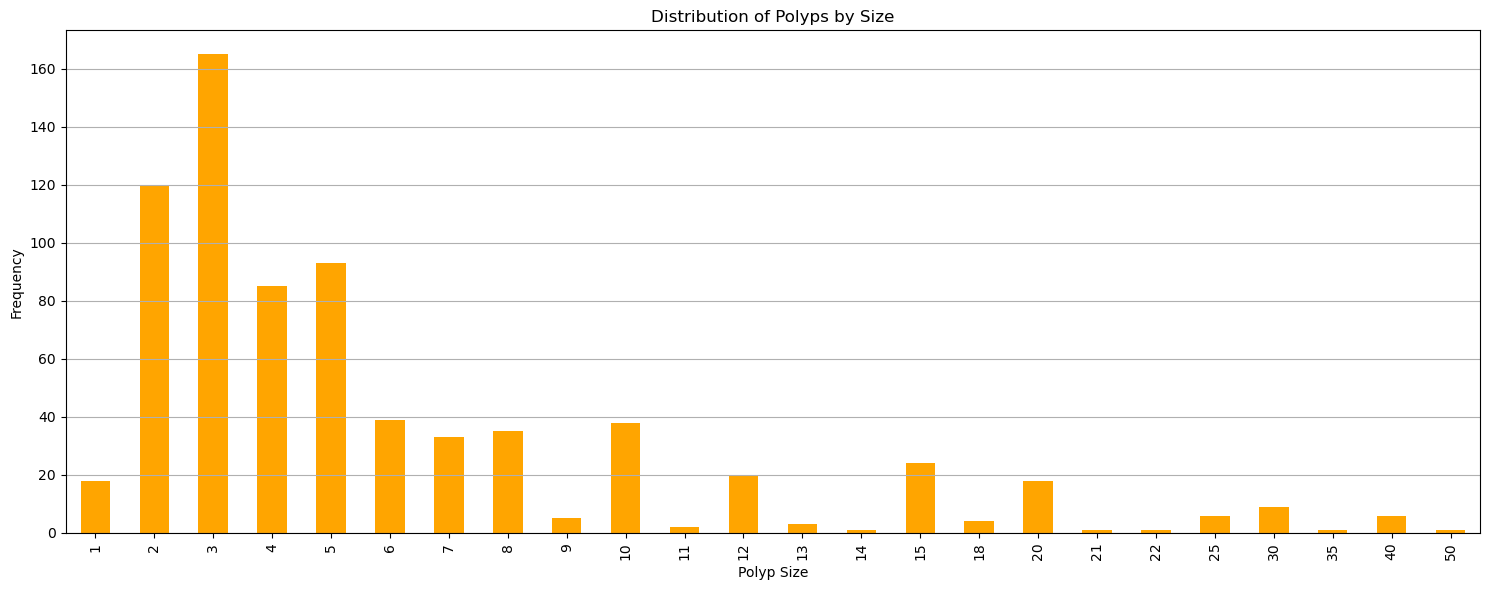

In [53]:
# Remove entries with negative values

polar_data = polar_data[polar_data['POLYP SIZE'] >= 0]
size_distribution_filtered = polar_data['POLYP SIZE'].value_counts().sort_index()

# Plot histograms for the distribution of polyps by size for both sets
plt.figure(figsize=(15, 6))
size_distribution_filtered.plot(kind='bar', color='orange')
plt.title('Distribution of Polyps by Size')
plt.xlabel('Polyp Size')
plt.ylabel('Frequency')
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [54]:
polar_data.shape[0]

728

In [0]:
# Distribution of polyp sizes. Descriptive statistics (excluding negative values)

In [16]:
polar_data['POLYP SIZE'].describe()

count    728.000000
mean       6.350275
std        6.380602
min        1.000000
25%        3.000000
50%        4.000000
75%        7.000000
max       50.000000
Name: POLYP SIZE, dtype: float64

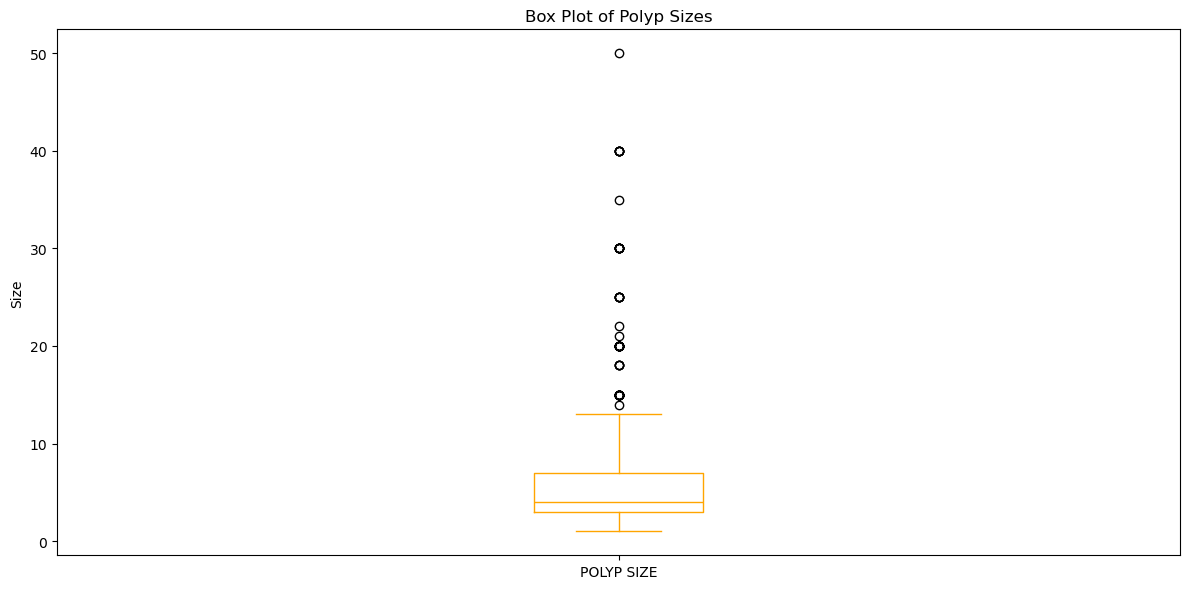

In [17]:
# Generate vertical box plots for the polyp sizes in the training and validation sets
plt.figure(figsize=(12, 6))
polar_data['POLYP SIZE'].plot(kind='box', color='orange')
plt.title('Box Plot of Polyp Sizes')
plt.ylabel('Size')
plt.tight_layout()
plt.show()

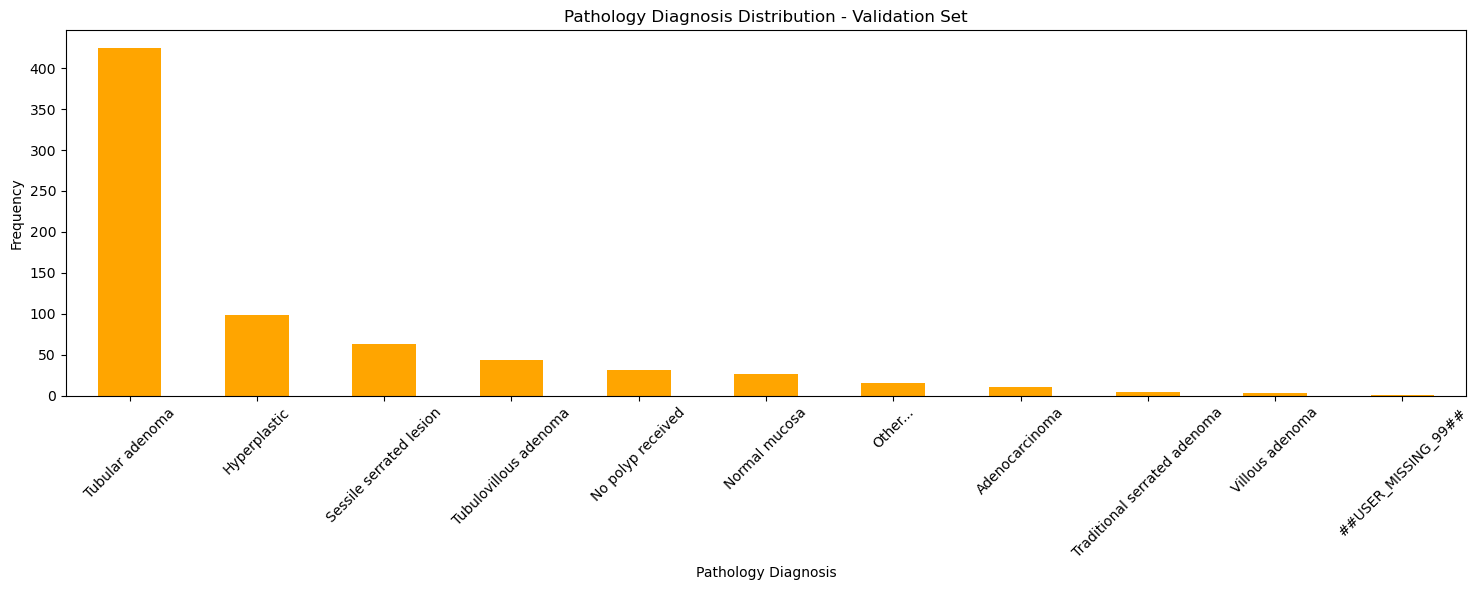

In [18]:
# Calculate the distribution of polyps by pathology diagnosis
pathology_distribution = polar_data['PATHOLOGY DIAGNOSIS'].value_counts()

# Generate histograms for the distribution of polyps by pathology diagnosis
plt.figure(figsize=(15, 6))
pathology_distribution.plot(kind='bar', color='orange')
plt.title('Pathology Diagnosis Distribution - Validation Set')
plt.xlabel('Pathology Diagnosis')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Distribution of polyps per patient.

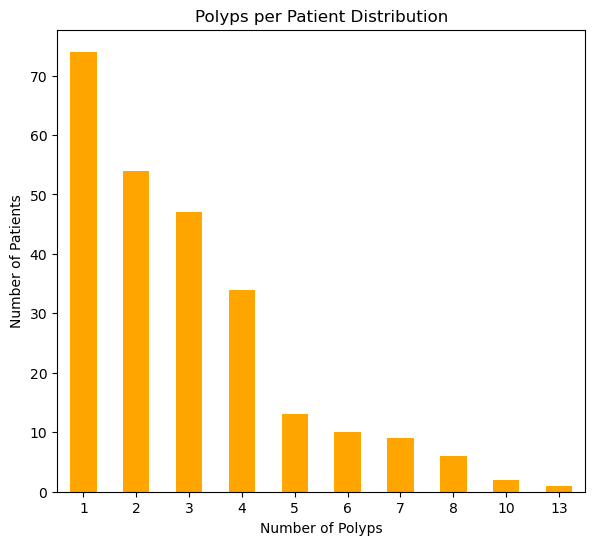

In [19]:
polyps_per_patient_validation_original = polar_data.groupby('PATIENT_ID')['POLYP/IMAGE_ID'].count()
polyps_per_patient_validation_distribution_original = polyps_per_patient_validation_original.value_counts().sort_index()

# Calculate the descriptive statistics for the number of polyps per patient in the original sets
desc_stats_polyps_per_patient_validation_original = polyps_per_patient_validation_original.describe()

# Generate histograms for the revised distribution of polyps per patient
plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 2)
polyps_per_patient_validation_distribution_original.plot(kind='bar', color='orange')
plt.title('Polyps per Patient Distribution')
plt.xlabel('Number of Polyps')
plt.ylabel('Number of Patients')
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Location analysis. Descriptive statistics

In [55]:
# Function to parse the polyp position and extract x and y coordinates
def extract_coordinates(positions):
    coordinates = positions.str.strip('[]').str.split(',', expand=True).astype(int)
    x = coordinates[0]
    y = coordinates[1]
    return x, y

# Extract coordinates
x_original, y_original = extract_coordinates(polar_data['POLYP POSITION (x,y,w,h)'])

# Generate descriptive statistics for the polyp positions
desc_stats_positions_original = pd.concat([x_original, y_original], axis=1).describe()

desc_stats_positions_original

,0,1
count,728.000000,728.000000
mean,461.078297,360.112637
std,243.311345,193.076258
min,0.000000,0.000000
25%,289.500000,234.500000
50%,451.500000,355.500000
75%,617.000000,502.250000
max,1442.000000,892.000000


In [ ]:
# We identify the entries with negative coordinate values

In [56]:
# Function to check for negative values in the position data
def has_negative_values(position):
    coordinates = position.strip('[]').split(',')
    return any(int(coord) < 0 for coord in coordinates)

# Identifying the entries with negative coordinates
negative_coords = polar_data[polar_data['POLYP POSITION (x,y,w,h)'].apply(has_negative_values)]

# Displaying the entries with negative coordinates along with Patient ID
negative_coords[['PATIENT_ID', 'POLYP/IMAGE_ID', 'POLYP POSITION (x,y,w,h)']]

,PATIENT_ID,POLYP/IMAGE_ID,"POLYP POSITION (x,y,w,h)"


In [ ]:
# Location analysis. Are there bounding boxes that exceed the boundaries of the images? 

In [25]:
def check_boundary_overflow(df):
    """
    Function to check if the polyp locations exceed the image boundaries.
    """
    # Extracting polyp positions and converting them to numeric values
    df['x'], df['y'], df['w'], df['h'] = zip(*df['POLYP POSITION (x,y,w,h)'].apply(lambda x: eval(x)))

    # Checking if the polyp locations exceed the image boundaries
    df['OVERFLOWS_WIDTH'] = (df['x'] + df['w']) > df['WIDTH']
    df['OVERFLOWS_HEIGHT'] = (df['y'] + df['h']) > df['HEIGHT']

    # Returning rows where either width or height is exceeded
    return df[(df['OVERFLOWS_WIDTH']) | (df['OVERFLOWS_HEIGHT'])]

def update_boundary_overflow_reason(df):
    """
    Update the boundary overflow reason to handle cases where both width and height are exceeded.
    """
    def determine_overflow_reason(row):
        if row['OVERFLOWS_WIDTH'] and row['OVERFLOWS_WIDTH']:
            return 'W+H'
        elif row['OVERFLOWS_WIDTH']:
            return 'W'
        elif row['OVERFLOWS_WIDTH']:
            return 'H'
        else:
            return 'None'

    df['OVERFLOW'] = df.apply(determine_overflow_reason, axis=1)
    return df

# Checking for boundary overflow
polar_data_w_overflow = check_boundary_overflow(polar_data.copy())
polar_data_w_overflow = update_boundary_overflow_reason(polar_data_w_overflow)

polar_data_w_overflow


,PATIENT_ID,POLYP/IMAGE_ID,"POLYP POSITION (x,y,w,h)",POLYP MORPHOLOGY,POLYP SIZE,POLYP LOCATION,OPTICAL DIAGNOSIS,OPTCAL DIAGNOSIS CONFIDENCE,PATHOLOGY DIAGNOSIS,WIDTH,HEIGHT,x,y,w,h,OVERFLOWS_WIDTH,OVERFLOWS_HEIGHT,OVERFLOW
64,028163bfb8814a028cbf2e8e0401cd34,5131f44e-7026-479c-b26b-686c8855eca2,"[553, 116, 794, 951]",Pedunculated,15,Sigmoid colon,Adenoma,High,Tubular adenoma,1155,990,553,116,794,951,True,True,W+H


In [ ]:
# We need to calculate the maximum value for these coordinates to fix this issue

In [57]:
def adjust_polyp_dimensions_override(df):
    """
    Adjust the width or height of the polyp position if they exceed the image boundaries and override the original values.
    """
    # Extracting polyp positions and converting them to numeric values
    df['x'], df['y'], df['w'], df['h'] = zip(*df['POLYP POSITION (x,y,w,h)'].apply(lambda x: eval(x)))

    # Adjusting width and height if they exceed image boundaries
    df['w'] = df.apply(lambda row: min(row['w'], row['WIDTH'] - row['x']), axis=1)
    df['h'] = df.apply(lambda row: min(row['h'], row['HEIGHT'] - row['y']), axis=1)

    # Updating the POLYP POSITION column with the adjusted values
    df['POLYP POSITION (x,y,w,h)'] = df.apply(lambda row: f"[{row['x']}, {row['y']}, {row['w']}, {row['h']}]", axis=1)

    return df

polar_data = adjust_polyp_dimensions_override(polar_data)

In [58]:
# Checking if there is still boundary overflow
polar_data_w_overflow = check_boundary_overflow(polar_data.copy())
polar_data_w_overflow = update_boundary_overflow_reason(polar_data_w_overflow)

polar_data_w_overflow

,PATIENT_ID,POLYP/IMAGE_ID,"POLYP POSITION (x,y,w,h)",POLYP MORPHOLOGY,POLYP SIZE,POLYP LOCATION,OPTICAL DIAGNOSIS,OPTCAL DIAGNOSIS CONFIDENCE,PATHOLOGY DIAGNOSIS,WIDTH,HEIGHT,x,y,w,h,OVERFLOWS_WIDTH,OVERFLOWS_HEIGHT,OVERFLOW


In [0]:
# Polyp morphology

In [29]:
# Analyzing the distribution of POLYP MORPHOLOGY
polar_data['POLYP MORPHOLOGY'].value_counts()

POLYP MORPHOLOGY
Sessile                495
Flat elevated          106
Pedunculated            93
Flat                    22
Depressed                4
Stenosing                3
##USER_MISSING_97##      3
##USER_MISSING_99##      2
Name: count, dtype: int64

In [59]:
polar_data = polar_data[~polar_data['POLYP MORPHOLOGY'].isin(['##USER_MISSING_97##', '##USER_MISSING_99##', 'Stenosing'])]

In [60]:
morphology_to_code = {
    'Sessile': 'Is',
    'Flat elevated': 'IIa',
    'Pedunculated': 'Ip',
    'Flat': 'IIb',
    'Depressed': 'IIc'
}

# Replace the 'POLYP MORPHOLOGY' values based on the mapping
polar_data['POLYP MORPHOLOGY'] = polar_data['POLYP MORPHOLOGY'].replace(morphology_to_code)
polar_data.rename(columns={'POLYP MORPHOLOGY': 'SHAPE'}, inplace=True)

In [ ]:
# Copy images from the subdirectories to a target img folder

In [38]:
import shutil
# destination path
destination_image_directory = os.path.dirname(spreadsheet_path) + '/img/'
# Create the base destination folder if it doesn't exist
os.makedirs(destination_image_directory, exist_ok=True)

for idx, row in polar_data.iterrows():
        patient_folder = os.path.join(validation_folder_path, row['PATIENT_ID'])
        image_id = row['POLYP/IMAGE_ID']
        source_file = os.path.join(patient_folder, image_id + ".png")
        destination_file = os.path.join(destination_image_directory, image_id + ".png")
        if os.path.exists(source_file):
            shutil.copy(source_file, destination_file)

In [61]:
polar_data.drop(columns=['PATIENT_ID', 'POLYP LOCATION', 'OPTICAL DIAGNOSIS', 'OPTCAL DIAGNOSIS CONFIDENCE', 'PATHOLOGY DIAGNOSIS', 'x', 'y', 'w', 'h'], inplace=True)

In [62]:
# Frame field

In [63]:
polar_data.rename(columns={'POLYP/IMAGE_ID': 'FRAME'}, inplace=True)
polar_data['FRAME'] = polar_data['FRAME'] + '.png'

In [64]:
# Size field

In [65]:
polar_data.rename(columns={'POLYP SIZE': 'SIZE'}, inplace=True)

In [66]:
# Image type

In [67]:
polar_data['IMAGE TYPE'] = 'NBI'

In [68]:
# Bounding boxes

In [69]:
# Transform the 'BOUNDING BOX' values
def transform_bounding_box(bbox_str):
    # Strip the square brackets, split by commas, and convert to integers
    bbox_components = list(map(int, bbox_str.strip('[]').split(',')))
    x, y, width, height = bbox_components
    # Calculate x max and y max
    x_max = x + width
    y_max = y + height
    # Return the formatted string
    return f"{x},{y},{x_max},{y_max}"

polar_data.rename(columns={'POLYP POSITION (x,y,w,h)': 'BOUNDING BOX'}, inplace=True)
polar_data['BOUNDING BOX'] = polar_data['BOUNDING BOX'].apply(transform_bounding_box)

In [71]:
polar_data.head()

,FRAME,BOUNDING BOX,SHAPE,SIZE,WIDTH,HEIGHT,IMAGE TYPE
0,57781dbd-5c47-4e9f-985e-62a9077ea9c5.png,"75,468,335,793",Is,3,1350,1080,NBI
1,ddb3f8d6-1f22-4576-8f74-d9d4751a48da.png,"62,593,498,982",Ip,5,1350,1080,NBI
2,64319dc0-e72d-4902-8084-ecdc17136bdd.png,"747,613,937,836",Is,4,1350,1080,NBI
3,bc673cdc-2e3a-41c7-8b37-cf289a3e42d5.png,"641,726,806,888",Is,3,1350,1080,NBI
4,8f155836-88df-4521-980e-5145a183879c.png,"435,28,754,265",Is,4,1350,1080,NBI


In [72]:
# Saving the data to a spreadsheet
save_path = os.path.join(os.path.dirname(spreadsheet_path), 'data-refined.xlsx')
polar_data.to_excel(save_path, index=False)